## ResNet Evaluation (2)

Evaluate ResNet trained to recognize the 5 wild bee species used for the XAI experiment with humans.

In [1]:
import sys
sys.path.append('./wingbeats/')

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.utils import metafile_readers as mr # an extra prefix beexplainable. may be needed
from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from wingbeats import modelling as wm # for building simple classifiers

In [3]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2023-08-17 18:16:37.706077: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2023-08-17 18:16:38.264260: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 46962 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [4]:
bees_subfolder = '5_species/'
dataset_folder = 'Bees_Christian_masked_bbox/Whole/'
metafolder = './beexplainable/metafiles/Bees_Christian/'

BEES_PATH = '../data/Wildbienen/' + dataset_folder
IMAGES_PATH = metafolder + 'images_5.txt'
IMAGES_LABELS_PATH = metafolder + bees_subfolder + 'image_class_labels.txt'
CLASSES_PATH = metafolder + bees_subfolder + 'classes.txt'
CONCEPTS_PATH = metafolder + bees_subfolder + 'concepts.txt'

MODELS_PATH  = './beexplainable/models/'
FIGURES_PATH = './beexplainable/figures/'

## Load images

In [5]:
batch_size = 64
img_height = img_width = 224

In [6]:
# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
file_ids = list( img_dict.keys() )
y_true   = list( img_label_dict.values() )
y_true   = np.asarray(y_true, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0

# Read class names and concepts
cls_dict = mr.metafile_to_dict(CLASSES_PATH)
classes = list( cls_dict.values() )
con_dict = mr.metafile_to_dict(CONCEPTS_PATH)
concepts = list( con_dict.values() )

In [7]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids,
                                                                           list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, BEES_PATH),
                                          label)

2023-08-17 18:26:12.031342: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 46962 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [8]:
# Conversion to tf.Dataset
test_set = ps.parse_to_dataset(file_ids, y_true, parse_image_lab)
test_set = test_set.cache().shuffle(len(y_true)).batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
test_set = test_set.map(lambda x, y: (normalization_layer(x), y))

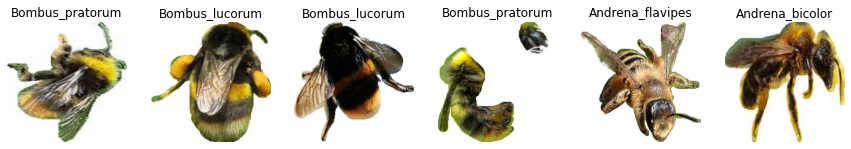

In [9]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = min(6, batch_size)
with tf.device('/CPU:0'):
    for images, labels in test_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(cls_dict[str(labels[i].numpy()+1)])
            plt.axis("off")
plt.show()

In [10]:
for image_batch, labels_batch in test_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

(64, 224, 224, 3)
tf.Tensor(4, shape=(), dtype=uint8)


## Evaluation on Test Set

In [12]:
# Define model parameters
in_shape = (img_width, img_height, 3)
drop_rate, lr, reg = 0.5, 1e-4, 1e-4 # lr and reg optimized in HPO notebook

constructor =  wm.build_simple_classifier
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top_3_accuracy')]

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
input_form = 'masked_bbox'
init = 'iNat' if load_pretrained_backbone else 'Imagenet'

out_shape = len(classes)
model_name = 'ResNet50_' + init + '_' + input_form + '_5spec_2' # model was trained on raw whole dataset
weights_file = MODELS_PATH + 'all/' + bees_subfolder + model_name + '/' + model_name + '.h5' # path to load weights from
print('Model loaded from ' + weights_file)

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not (must be set to True even if just loading weights and doing inference)
trainable = True

Model loaded from ./beexplainable/models/all/5_species/ResNet50_iNat_masked_bbox_5spec_2/ResNet50_iNat_masked_bbox_5spec_2.h5


In [ ]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(weights_file)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

In [15]:
# Test accuracy (on species labels)
model.evaluate(test_set, verbose = 1)

4/4 [==============================] - 0s 66ms/step - loss: 12.5229 - accuracy: 0.8519 - top_3_accuracy: 0.9861


[12.522880554199219, 0.8518518805503845, 0.9861111044883728]